## 07 - Topic labeling

I read the 30 topics, give each one a name and a category, and save the files used by the dashboard.

In [1]:
# --- IMPORTS ---
import warnings

# tqdm, used by BERTopic, warns at import that ipywidgets is missing. The warning prints a
# local path, so it is hidden before the imports that raise it.
warnings.filterwarnings("ignore", message="IProgress not found")

# Data and statistics
import numpy as np
import pandas as pd
from scipy.stats import binomtest, t

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter

# Topic model
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance

W1113 16:22:34.298000 36940 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
# --- LOAD DATA AND MODEL ---
# The reviews with their topic number, and the model, both saved by 06
italian_df = pd.read_csv("../data/processed/trenord_reviews_topics.csv")

# 06 trained the model on Italian reviews only, so the file must contain nothing else
assert (italian_df["language"] == "it").all(), "topics.csv contains non-Italian reviews"

# Only the name of the embedding model was saved in 06, so it is passed again here
topic_model = BERTopic.load(
    "../data/processed/bertopic_model_trained",
    embedding_model="paraphrase-multilingual-mpnet-base-v2"
)

print(f"Italian reviews loaded: {len(italian_df):,}")
print(f"Topics in the model   : {len(set(topic_model.topics_))}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 486.85it/s]


Italian reviews loaded: 6,951
Topics in the model   : 30


In [3]:
# --- CHECK: FILE AND MODEL AGREE ---
# 06 saves topics.csv and the model together. If one of them was replaced later,
# some reviews would have a different topic in the file and in the model.
file_topics = italian_df["topic"].tolist()
model_topics = list(topic_model.topics_)

same_topics = file_topics == model_topics
print(f"Same topic for every review in file and model: {same_topics}")

assert same_topics, "topics.csv and the model disagree: rerun 06 so they are saved together"

Same topic for every review in file and model: True


In [4]:
# --- TOPIC OVERVIEW: THE EVIDENCE BEHIND THE LABELS ---
# One row per topic with what was looked at to give it a label: size, average rating,
# share of negative and positive reviews, share of very short reviews (the exclusion rule)
# and the top 5 keywords. Review texts are not shown, because notebook outputs are published.
rows = []
for topic_id in sorted(italian_df["topic"].unique()):
    topic_reviews = italian_df[italian_df["topic"] == topic_id]

    keywords = []
    for word, weight in topic_model.get_topic(topic_id)[:5]:
        keywords.append(word)

    # (condition).mean() gives the share of reviews for which the condition is true
    rows.append({
        "topic": topic_id,
        "reviews": len(topic_reviews),
        "avg rating": round(topic_reviews["rating"].mean(), 2),
        "1-2 stars (%)": round((topic_reviews["rating"] <= 2).mean() * 100, 1),
        "4-5 stars (%)": round((topic_reviews["rating"] >= 4).mean() * 100, 1),
        "5 words or fewer (%)": round((topic_reviews["word_count"] <= 5).mean() * 100, 1),
        "top keywords": ", ".join(keywords),
    })

topic_overview = pd.DataFrame(rows).set_index("topic")

# Show the keyword lists in full instead of cutting them
pd.set_option("display.max_colwidth", None)
topic_overview

,reviews,avg rating,1-2 stars (%),4-5 stars (%),5 words or fewer (%),top keywords
topic,,,,,,
0,1214,1.81,77.5,14.3,1.2,"treni, treno, ritardi, app, stazione"
1,1143,1.41,88.9,5.2,1.7,"biglietti, acquistare biglietti, app, acquisto, errore"
2,641,1.44,87.8,5.3,3.4,"pagamento, abbonamenti, rinnovare abbonamento, credito, carta credito"
3,499,1.43,88.2,5.8,51.9,"lenta, inutile, inaffidabile, difficile, incomprensibile"
4,515,1.54,83.1,8.0,9.3,"app, aggiornamento, telefono, android, problema"
5,219,1.45,88.6,3.7,3.7,"login, account, accesso, errore, mail"
6,185,1.75,80.5,11.4,11.9,"ritardi, ritardo, ritardi cancellazioni, arrivano ritardo, aggiornamento reale"
7,173,1.68,80.9,9.2,4.0,"stazioni, stazione, stazioni preferite, aggiornamento, reinstallato"
8,176,4.27,11.9,86.4,25.6,"ottima app, app comoda, app facile, app funziona, app veloce"


In [5]:
# --- LABEL MAP ---

EXCLUDE = "EXCLUDE"

TOPIC_LABELS = {
    # Inaccurate Train Info: delays and cancellations shown late, wrong or not at all (0, 6 and 29 share this label)
    0:  ("Inaccurate Train Info", "App Issue", ["treni", "ritardi"]),
    # Tickets that cannot be bought, errors at checkout
    1:  ("Ticket Purchase Failures", "App Issue", ["biglietti", "errore"]),
    # Subscription & Payment Failures: subscription renewals and card payments that fail
    2:  ("Subscription & Payment Failures", "App Issue", ["pagamento", "abbonamenti"]),
    # Borderline: 52% of reviews are short, but it is the only topic about a slow, unclear app
    3:  ("Poor Usability", "App Issue", ["lenta", "difficile"]),
    # App Not Working: the app stops working or does not open, often after an update.
    # It also holds generic "it does not work" reviews that do not say what fails.
    4:  ("App Not Working", "App Issue", ["aggiornamento", "android"]),
    # Login and account problems
    5:  ("Login & Account Issues", "App Issue", ["login", "account"]),
    # Inaccurate Train Info: short reviews saying delays are not shown in real time
    6:  ("Inaccurate Train Info", "App Issue", ["ritardi", "ritardi cancellazioni"]),
    # Station Issues: favourite stations lost, station search not working. Shares the label
    # with topic 28, because the two were hard to tell apart.
    7:  ("Station Issues", "App Issue", ["stazioni", "stazioni preferite"]),
    # The app is convenient and easy to use
    8:  ("Ease of Use", "Praise", ["app comoda", "app facile"]),
    # Excluded (73% short): generic praise; "utilissima" and "efficace" make it a borderline case
    9:  (EXCLUDE, None, ["ottima applicazione", "utilissima"]),
    # Excluded (99% short): one-word praise
    10: (EXCLUDE, None, ["ottima", "perfetta"]),
    # Short, but names specific qualities: easy, simple, intuitive
    11: ("Ease of Use", "Praise", ["facile", "intuitivo"]),
    # Easy Purchases: buying tickets in the app is easy
    12: ("Easy Purchases", "Praise", ["biglietti", "facile"]),
    # QR code of the ticket missing or not read at the metro gates
    13: ("QR Code Failures", "App Issue", ["codice", "metro"]),
    # Excluded (90% short): generic praise of the service
    14: (EXCLUDE, None, ["ottimo", "complimenti"]),
    # App Not Working: problems that started after an update
    15: ("App Not Working", "App Issue", ["aggiornamento", "bug"]),
    # Excluded (64% short): "it works" without saying what
    16: (EXCLUDE, None, ["funziona funziona", "funzionante"]),
    # Easy Purchases: paying for subscriptions in the app is fast
    17: ("Easy Purchases", "Praise", ["pagamento", "rapido"]),
    # Improvement Feedback: how the app got better or worse with an update, and how it could improve
    18: ("Improvement Feedback", "App Updates", ["migliorata", "migliorare"]),
    # Train Service Complaints: about the trains and the company, not the app
    19: ("Train Service Complaints", "Rail Service", ["servizio pessimo", "azienda"]),
    # Short, but names specific qualities: efficient, fast
    20: ("Ease of Use", "Praise", ["efficiente", "rapida"]),
    # Excluded (72% short): vague remarks ("does its job"), strikes, no clear theme
    21: (EXCLUDE, None, ["dovere", "sufficiente"]),
    # Registration problems, part of the same account process as topic 5
    22: ("Login & Account Issues", "App Issue", ["registrare", "profilo"]),
    # Excluded (78% short): "ottima app" and nothing else
    23: (EXCLUDE, None, ["ottima app", "buona app"]),
    # Short, but names specific qualities: easy and fast
    24: ("Ease of Use", "Praise", ["facile veloce", "semplice veloce"]),
    # Excluded (98% short): one-word negative verdicts
    25: (EXCLUDE, None, ["pessima pessima", "negativa"]),
    # Excluded (82% short): "it does not work" without saying what
    26: (EXCLUDE, None, ["funziona", "impossibile utilizzare"]),
    # Excluded (92% short): one-word negative verdicts
    27: (EXCLUDE, None, ["pessima pessima", "disastrosa"]),
    # Station Issues: stations removed from the app or missing from its list. Shares the label
    # with topic 7, because the two were hard to tell apart.
    28: ("Station Issues", "App Issue", ["milano", "alcune stazioni"]),
    # Inaccurate Train Info: delays the app does not report
    29: ("Inaccurate Train Info", "App Issue", ["ritardi", "app aggiornata"]),
}

In [6]:
# --- CHECK THE LABEL MAP ---
# Check 1: every topic of the model has exactly one entry in the map
model_topic_ids = sorted(set(topic_model.topics_))
assert sorted(TOPIC_LABELS) == model_topic_ids, "The map and the model do not have the same topics"

# Check 2: every topic still has its two keywords among its top 10 keywords.
# If one is missing, the model has changed since the labels were written.
missing_keywords = []
for topic_id, entry in TOPIC_LABELS.items():
    # entry is (label, category, keywords): the keywords are the third element
    anchors = entry[2]

    topic_words = []
    for word, weight in topic_model.get_topic(topic_id):
        topic_words.append(word)

    for anchor in anchors:
        if anchor not in topic_words:
            missing_keywords.append(f"topic {topic_id}: {anchor}")

print(f"Topics in the map : {len(TOPIC_LABELS)}")
print(f"Keywords not found: {len(missing_keywords)}")

assert len(missing_keywords) == 0, "The model has changed, the labels must be rebuilt: " + ", ".join(missing_keywords)

Topics in the map : 30
Keywords not found: 0


In [7]:
# --- APPLY THE LABELS ---
# Every review gets the label and the category of its topic.
label_by_topic = {}
category_by_topic = {}
for topic_id, entry in TOPIC_LABELS.items():
    label_by_topic[topic_id] = entry[0]
    category_by_topic[topic_id] = entry[1]

# map() replaces each topic number with its label or category
italian_df["topic_label"] = italian_df["topic"].map(label_by_topic)
italian_df["category"] = italian_df["topic"].map(category_by_topic)

# No review should be left without a label
assert italian_df["topic_label"].notna().all(), "Some reviews have no label"

kept_reviews = italian_df[italian_df["topic_label"] != EXCLUDE]
excluded_reviews = italian_df[italian_df["topic_label"] == EXCLUDE]

print(f"Labels, excluding EXCLUDE: {kept_reviews['topic_label'].nunique()}")
print(f"Reviews kept             : {len(kept_reviews):,}")
print(f"Reviews excluded         : {len(excluded_reviews):,}")
print(f"Share excluded           : {len(excluded_reviews) / len(italian_df) * 100:.1f}%")

Labels, excluding EXCLUDE: 12
Reviews kept             : 5,998
Reviews excluded         : 953
Share excluded           : 13.7%


In [8]:
# --- WHICH TOPICS TO MERGE ---
# Topics with the same label are merged. The list comes from the label map,
# so it cannot disagree with it. Excluded topics are left as they are.
topics_by_label = {}
for topic_id, entry in TOPIC_LABELS.items():
    label = entry[0]
    if label == EXCLUDE:
        continue
    if label not in topics_by_label:
        topics_by_label[label] = []
    topics_by_label[label].append(topic_id)

# Only labels with more than one topic need a merge
topics_to_merge = []
for label, topic_ids in topics_by_label.items():
    if len(topic_ids) > 1:
        topics_to_merge.append(topic_ids)
        print(f"{label}: topics {topic_ids}")

Inaccurate Train Info: topics [0, 6, 29]
App Not Working: topics [4, 15]
Login & Account Issues: topics [5, 22]
Station Issues: topics [7, 28]
Ease of Use: topics [8, 11, 20, 24]
Easy Purchases: topics [12, 17]


In [9]:
# --- MERGE THE TOPICS ---
# merge_topics() needs the texts in the same order as the model's assignments,
# with empty texts replaced by a space, as in 06
texts = italian_df["text_clean"].tolist()
for i in range(len(texts)):
    is_valid = isinstance(texts[i], str) and len(texts[i].strip()) > 0
    if not is_valid:
        texts[i] = " "

# The saved model does not keep MMR, so it is set again with the same diversity as in 06
topic_model.representation_model = MaximalMarginalRelevance(diversity=0.3)
topic_model.merge_topics(texts, topics_to_merge)

# After a merge BERTopic renumbers all topics by size, so the new numbers go in their own column
italian_df["topic_merged"] = topic_model.topics_
print(f"Topics after the merge: {italian_df['topic_merged'].nunique()}")

Topics after the merge: 21


In [10]:
# --- CHECK THE MERGE ---
# Each merged topic must hold a single label
labels_per_merged_topic = italian_df.groupby("topic_merged")["topic_label"].nunique()
assert (labels_per_merged_topic == 1).all(), "A merged topic contains more than one label"

# Each kept label must be a single merged topic
kept_reviews = italian_df[italian_df["topic_label"] != EXCLUDE]
merged_topics_per_label = kept_reviews.groupby("topic_label")["topic_merged"].nunique()
assert (merged_topics_per_label == 1).all(), "A label is split across more than one merged topic"

# The merged model keeps one topic per kept label and leaves each excluded topic alone
n_kept_labels = len(topics_by_label)
n_excluded_topics = 0
for topic_id, entry in TOPIC_LABELS.items():
    if entry[0] == EXCLUDE:
        n_excluded_topics += 1
n_merged_topics = len(set(topic_model.topics_))
assert n_merged_topics == n_kept_labels + n_excluded_topics, "The merged model does not have one topic per label plus the excluded topics"

print("Every merged topic holds one label, and every label is one merged topic")
print(f"Topics in the merged model: {n_merged_topics} ({n_kept_labels} labels and {n_excluded_topics} excluded)")

Every merged topic holds one label, and every label is one merged topic
Topics in the merged model: 21 (12 labels and 9 excluded)


In [11]:
# --- FINAL TOPICS ---
# One row per label: size, share of the analysis set, average rating and its 95% confidence
# interval. The interval shows how precise each average is: topics with few reviews have
# wider intervals, so their averages are less certain. Reviews are treated as independent.
analysis_df = italian_df[italian_df["topic_label"] != EXCLUDE].copy()
n_analysis = len(analysis_df)

rows = []
for label in analysis_df["topic_label"].unique():
    topic_reviews = analysis_df[analysis_df["topic_label"] == label]
    ratings = topic_reviews["rating"]
    n = len(ratings)

    # Standard error: how much the average would change from one sample to another
    standard_error = ratings.std() / np.sqrt(n)
    # 95% margin from the t distribution, with n - 1 degrees of freedom
    margin = t.ppf(0.975, n - 1) * standard_error

    rows.append({
        "label": label,
        "category": topic_reviews["category"].iloc[0],
        "reviews": n,
        "share (%)": round(n / n_analysis * 100, 1),
        "avg rating": round(ratings.mean(), 2),
        "95% CI low": round(ratings.mean() - margin, 2),
        "95% CI high": round(ratings.mean() + margin, 2),
    })

final_topics = pd.DataFrame(rows).sort_values("reviews", ascending=False).set_index("label")
display(final_topics)

# Reviews per category
category_counts = analysis_df["category"].value_counts()
category_table = pd.DataFrame({
    "reviews": category_counts,
    "share (%)": (category_counts / n_analysis * 100).round(1),
})
category_table

,category,reviews,share (%),avg rating,95% CI low,95% CI high
label,,,,,,
Inaccurate Train Info,App Issue,1501,25.0,1.78,1.72,1.84
Ticket Purchase Failures,App Issue,1143,19.1,1.41,1.36,1.46
App Not Working,App Issue,655,10.9,1.61,1.53,1.69
Subscription & Payment Failures,App Issue,641,10.7,1.44,1.37,1.51
Poor Usability,App Issue,499,8.3,1.43,1.35,1.51
Ease of Use,Praise,463,7.7,4.54,4.45,4.62
Login & Account Issues,App Issue,289,4.8,1.40,1.31,1.49
Easy Purchases,Praise,277,4.6,3.98,3.82,4.14
Station Issues,App Issue,244,4.1,1.73,1.58,1.88


,reviews,share (%)
category,,
App Issue,5090,84.9
Praise,740,12.3
Rail Service,87,1.5
App Updates,81,1.4


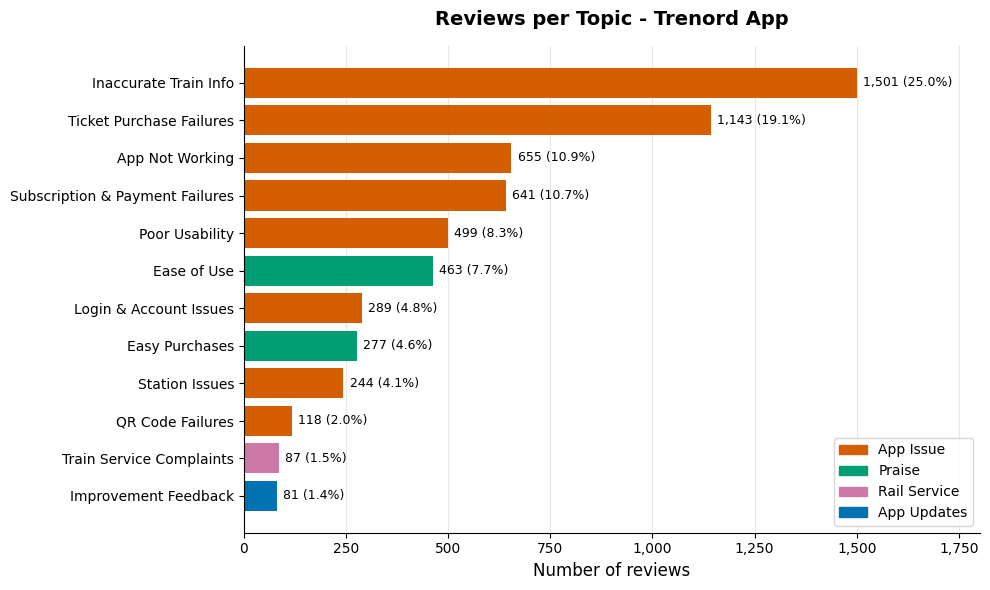

In [12]:
# --- CHART 1: REVIEWS PER TOPIC ---
# Horizontal bars, because topic names are long and read better on the left.
# The colour shows the category. Bars are drawn from the bottom, so the data is sorted
# from the smallest topic to the largest, which puts the largest at the top.

# Okabe-Ito colours: designed to stay distinct for readers with colour vision deficiency
CATEGORY_COLORS = {
    "App Issue": "#D55E00",
    "Praise": "#009E73",
    "Rail Service": "#CC79A7",
    "App Updates": "#0072B2",
}

chart_data = final_topics.sort_values("reviews")

bar_colors = []
for category in chart_data["category"]:
    bar_colors.append(CATEGORY_COLORS[category])

fig, ax = plt.subplots(figsize=(10, 6))

positions = range(len(chart_data))
ax.barh(positions, chart_data["reviews"], color=bar_colors)
ax.set_yticks(positions)
ax.set_yticklabels(chart_data.index)

# Number of reviews and share of the analysis set at the end of each bar
for i in range(len(chart_data)):
    reviews = chart_data["reviews"].iloc[i]
    share = chart_data["share (%)"].iloc[i]
    ax.text(reviews + 15, i, f"{reviews:,} ({share}%)", va="center", fontsize=9)

# One coloured square per category in the legend
legend_handles = []
for category, color in CATEGORY_COLORS.items():
    legend_handles.append(Patch(color=color, label=category))
ax.legend(handles=legend_handles, fontsize=10, loc="lower right")

ax.set_title("Reviews per Topic - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Number of reviews", fontsize=12)
ax.set_xlim(0, chart_data["reviews"].max() * 1.2)  # room for the labels at the end of the bars
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Light vertical grid behind the bars, to read the values more easily
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../reports/figures/chart_reviews_per_topic.png", dpi=150)
plt.show()

Each bar is one of the 12 topics, with its number of reviews and its share of the 5,998 analysed reviews. App Issue covers 8 of the 12 topics and 84.9% of the reviews, and the two largest topics, Inaccurate Train Info (25.0%) and Ticket Purchase Failures (19.1%), hold 44.1% together. Praise covers two topics and 12.3% of the reviews, and only 1.5% are about the trains or the company rather than the app.

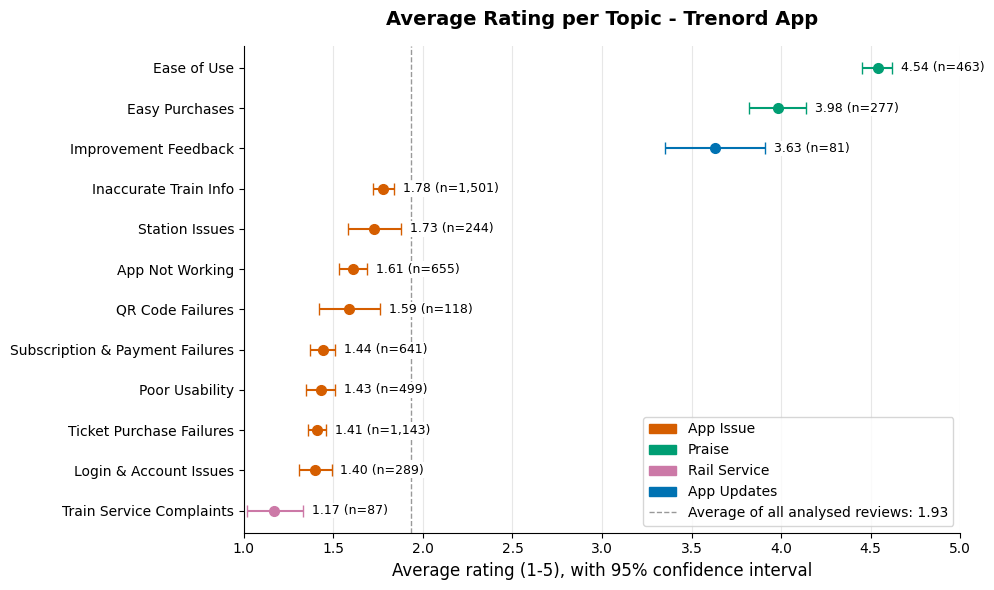

In [13]:
# --- CHART 2: AVERAGE RATING PER TOPIC ---
# A dot for each average instead of a bar: bars suggest a value that starts from zero,
# while ratings start from 1. The horizontal line through each dot is the 95% confidence
# interval from the final topics table: the shorter it is, the more precise the average.
# The axis covers the full 1-5 scale, so differences are not exaggerated.

# Sorted from the lowest average to the highest, which puts the highest at the top
chart_data = final_topics.sort_values("avg rating")

fig, ax = plt.subplots(figsize=(10, 6))

for i in range(len(chart_data)):
    avg = chart_data["avg rating"].iloc[i]
    ci_low = chart_data["95% CI low"].iloc[i]
    ci_high = chart_data["95% CI high"].iloc[i]
    n_reviews = chart_data["reviews"].iloc[i]
    color = CATEGORY_COLORS[chart_data["category"].iloc[i]]

    # xerr is the distance from the dot to each end of the interval: [[left], [right]]
    ax.errorbar(
        avg, i,
        xerr=[[avg - ci_low], [ci_high - avg]],
        fmt="o", color=color, markersize=7, capsize=4
    )
    # The average and the number of reviews, after the end of the interval.
    # The white background keeps the text readable where it crosses the reference line.
    ax.text(
        ci_high + 0.05, i, f"{avg:.2f} (n={n_reviews:,})",
        va="center", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1)
    )

positions = range(len(chart_data))
ax.set_yticks(positions)
ax.set_yticklabels(chart_data.index)

# Reference line: the average of all reviews in the analysis set
analysis_avg = analysis_df["rating"].mean()
average_line = ax.axvline(
    x=analysis_avg,
    color="black", linestyle="--", linewidth=1, alpha=0.4,
    label=f"Average of all analysed reviews: {analysis_avg:.2f}"
)

# Legend: one square per category, plus the reference line
legend_handles = []
for category, color in CATEGORY_COLORS.items():
    legend_handles.append(Patch(color=color, label=category))
legend_handles.append(average_line)
ax.legend(handles=legend_handles, fontsize=10, loc="lower right")

ax.set_title("Average Rating per Topic - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Average rating (1-5), with 95% confidence interval", fontsize=12)
ax.set_xlim(1, 5)  # honest scale: the full rating range

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Light vertical grid behind the dots, as in chart 1
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../reports/figures/chart_avg_rating_per_topic.png", dpi=150)
plt.show()

Each dot is the average rating of a topic and its line is the 95% confidence interval; long lines mean few reviews, as for Improvement Feedback (81). All App Issue topics have low averages, between 1.40 and 1.78 stars. The two Praise topics are far above, at 3.98 and 4.54 stars. The differences between the App Issue topics are small, at most 0.38 stars. Some are within the uncertainty: Ticket Purchase Failures (1.36 to 1.46) and Subscription & Payment Failures (1.37 to 1.51) have intervals that overlap, so their order should not be read as real. Train Service Complaints has the lowest average (1.17), and the two Praise topics and Improvement Feedback are far above all the others.

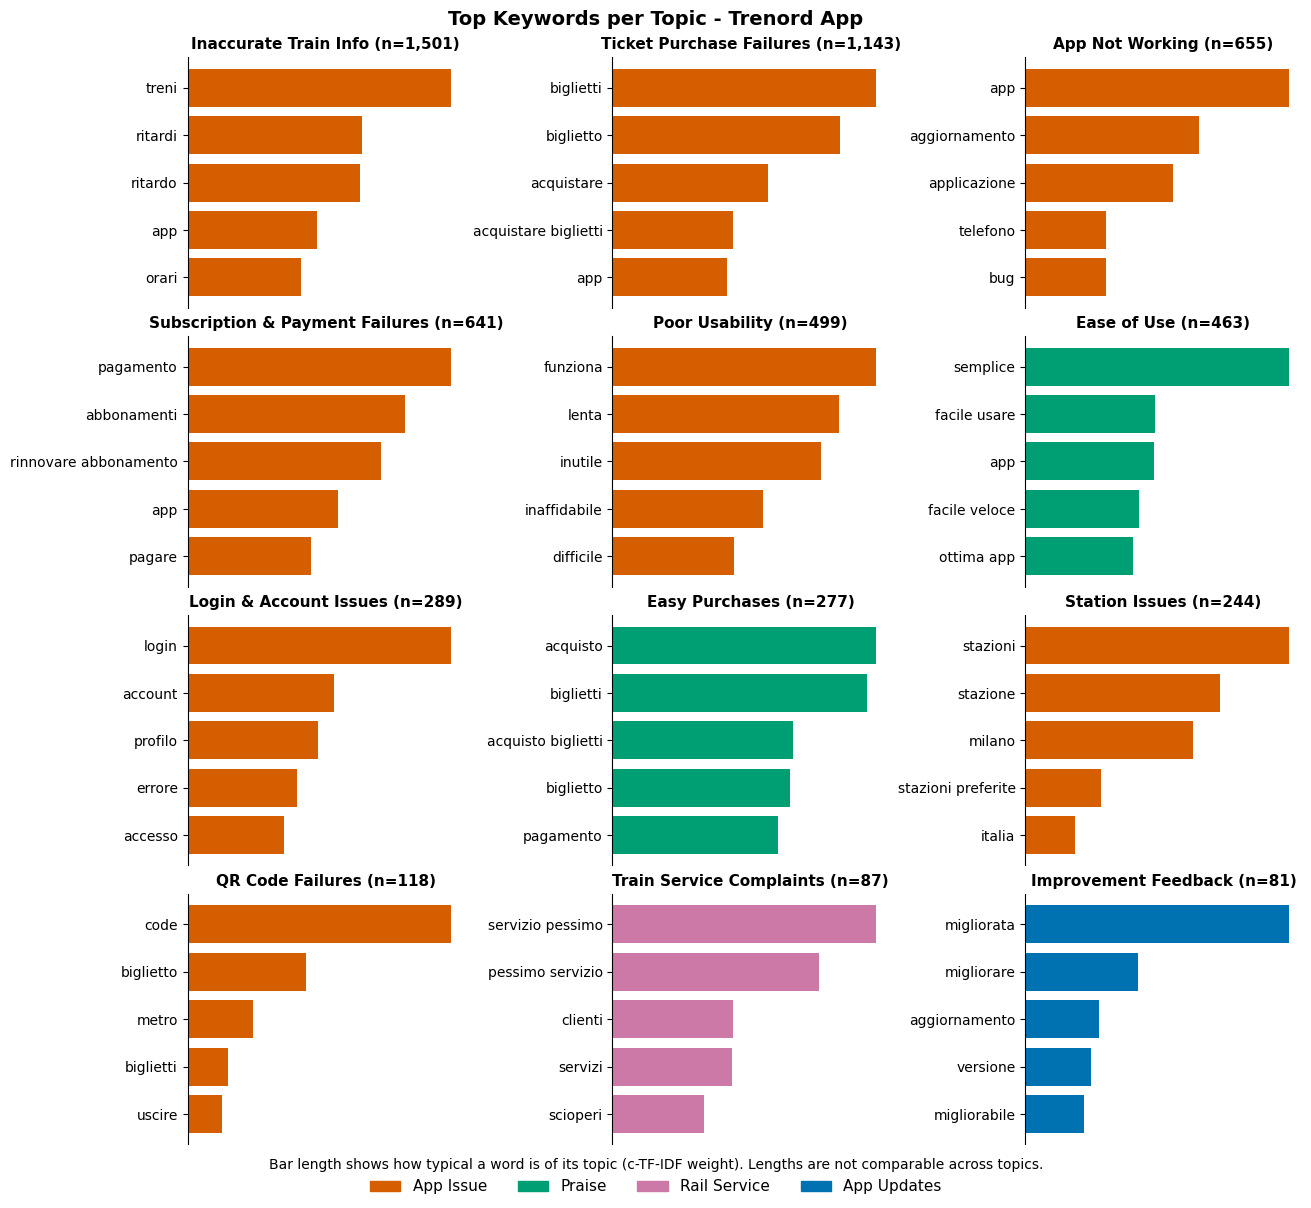

In [14]:
# --- CHART 3: KEYWORDS OF THE FINAL TOPICS ---
# The top 5 keywords of each of the 12 topics, taken from the merged model, so topics that
# share a label are described together. Bar length is the c-TF-IDF weight: how typical a
# word is of its own topic. Weights are not comparable across topics, so the axis has no
# numbers. Topics follow the order of chart 1, largest first.
N_WORDS = 5

# Merged topic number of each label (the merge check above showed that each label is one merged topic)
merged_id_by_label = {}
for label in final_topics.index:
    label_reviews = analysis_df[analysis_df["topic_label"] == label]
    merged_id_by_label[label] = label_reviews["topic_merged"].iloc[0]

# 3 columns x 4 rows = 12 panels, one per topic. constrained layout keeps panels,
# titles and labels from overlapping.
fig, axes = plt.subplots(4, 3, figsize=(13, 12), layout="constrained")
axes = axes.flatten()  # one simple list of panels, easier to loop over

for i in range(len(final_topics)):
    label = final_topics.index[i]
    ax = axes[i]

    words = []
    weights = []
    for word, weight in topic_model.get_topic(merged_id_by_label[label])[:N_WORDS]:
        words.append(word)
        weights.append(weight)

    # Bars are drawn from the bottom: reversing puts the strongest word at the top
    words.reverse()
    weights.reverse()

    color = CATEGORY_COLORS[final_topics.loc[label, "category"]]
    ax.barh(words, weights, color=color)

    n_reviews = final_topics.loc[label, "reviews"]
    ax.set_title(f"{label} (n={n_reviews:,})", fontsize=11, fontweight="bold")

    # No numbers on the axis: lengths are compared only within a topic
    ax.set_xticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)

# Panels left without a topic, if the map ever has fewer labels than panels, are hidden
for j in range(len(final_topics), len(axes)):
    axes[j].set_visible(False)

# One legend for the whole figure, in a single row under the panels. Its title explains the
# bars: a separate note at the bottom of the figure would overlap the legend.
legend_handles = []
for category, color in CATEGORY_COLORS.items():
    legend_handles.append(Patch(color=color, label=category))
fig.legend(
    handles=legend_handles, fontsize=11, loc="outside lower center", ncol=len(CATEGORY_COLORS), frameon=False,
    title="Bar length shows how typical a word is of its topic (c-TF-IDF weight). "
          "Lengths are not comparable across topics.",
    title_fontsize=10
)

fig.suptitle("Top Keywords per Topic - Trenord App", fontsize=14, fontweight="bold")

plt.savefig("../reports/figures/chart_keywords_per_topic.png", dpi=150)
plt.show()

Each panel shows the 5 most typical words of a topic after the merges, and bar lengths can be compared within a panel, not between panels. The keywords match the labels: "treni" and "ritardi" for Inaccurate Train Info, and "stazioni", "stazione" and "milano" for Station Issues, which joins two topics that were hard to tell apart, lost favourite stations and stations missing from the list. The top words of App Not Working are generic ("app", "aggiornamento", "applicazione"), because the label also holds reviews that only say the app does not work. The top word of Poor Usability is "funziona", most likely from "non funziona", which confirms that this topic is borderline.

Topic names that overlap: 0


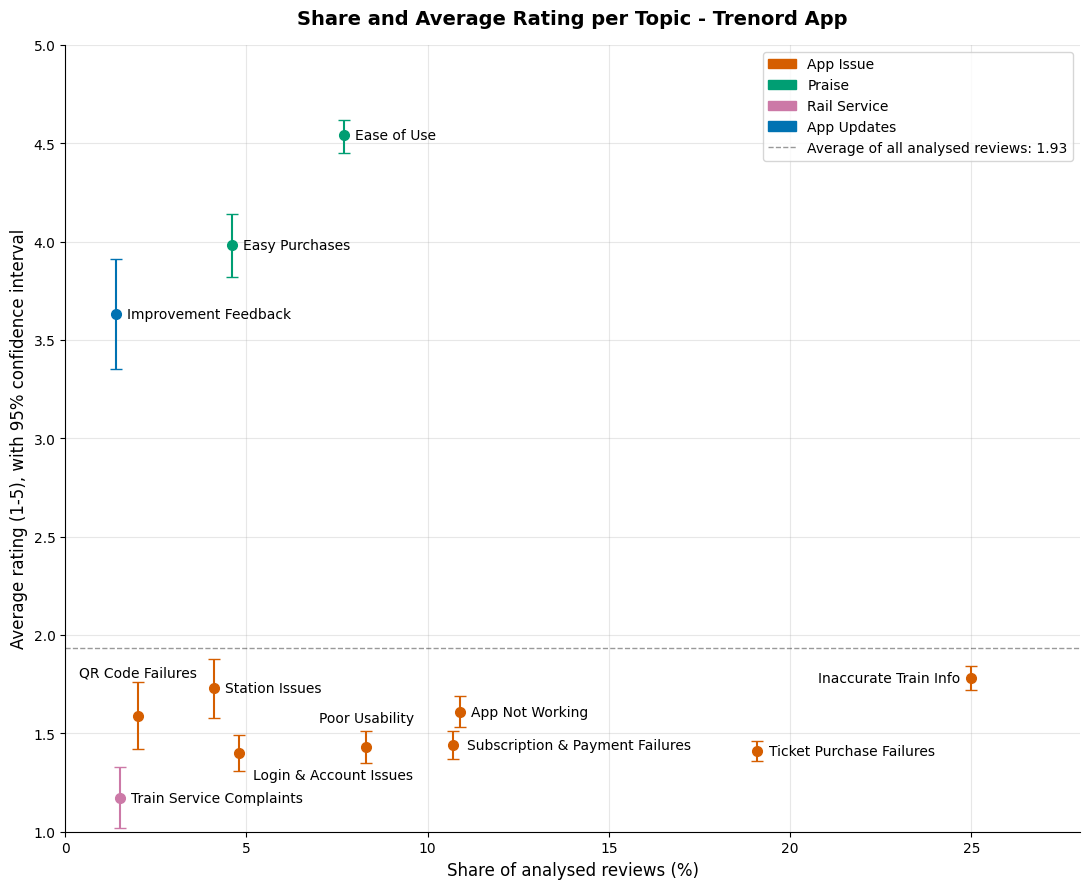

In [15]:
# --- CHART 4: SHARE AND AVERAGE RATING PER TOPIC ---
# One dot per topic: how often it is mentioned (x) against how it is rated (y). The vertical
# line through each dot is the 95% confidence interval of the average, from the final topics
# table. The y axis covers the full 1-5 scale, as in chart 2.

# Where each name goes, in points from its dot, with its alignment. Set by hand so that no two
# names overlap and no name crosses a dot or an interval.
LABEL_POSITIONS = {
    "Inaccurate Train Info": (-8, 0, "right", "center"),
    "Ticket Purchase Failures": (8, 0, "left", "center"),
    "App Not Working": (8, 0, "left", "center"),
    "Subscription & Payment Failures": (10, 0, "left", "center"),
    "Poor Usability": (0, 16, "center", "bottom"),
    "Ease of Use": (8, 0, "left", "center"),
    "Login & Account Issues": (10, -16, "left", "center"),
    "Easy Purchases": (8, 0, "left", "center"),
    "Station Issues": (8, 0, "left", "center"),
    "QR Code Failures": (0, 26, "center", "bottom"),
    "Train Service Complaints": (8, 0, "left", "center"),
    "Improvement Feedback": (8, 0, "left", "center"),
}

fig, ax = plt.subplots(figsize=(11, 9))

name_texts = []
for label in final_topics.index:
    share = final_topics.loc[label, "share (%)"]
    avg = final_topics.loc[label, "avg rating"]
    ci_low = final_topics.loc[label, "95% CI low"]
    ci_high = final_topics.loc[label, "95% CI high"]
    color = CATEGORY_COLORS[final_topics.loc[label, "category"]]

    # yerr is the distance from the dot to each end of the interval: [[below], [above]]
    ax.errorbar(
        share, avg,
        yerr=[[avg - ci_low], [ci_high - avg]],
        fmt="o", color=color, markersize=7, capsize=4
    )

    x_offset, y_offset, horizontal, vertical = LABEL_POSITIONS[label]
    name_text = ax.annotate(
        label, (share, avg), xytext=(x_offset, y_offset), textcoords="offset points",
        ha=horizontal, va=vertical, fontsize=10
    )
    name_texts.append(name_text)

# Reference line: the average of all reviews in the analysis set, as in chart 2
average_line = ax.axhline(
    y=analysis_avg,
    color="black", linestyle="--", linewidth=1, alpha=0.4,
    label=f"Average of all analysed reviews: {analysis_avg:.2f}"
)

legend_handles = []
for category, color in CATEGORY_COLORS.items():
    legend_handles.append(Patch(color=color, label=category))
legend_handles.append(average_line)
ax.legend(handles=legend_handles, fontsize=10, loc="upper right")

ax.set_title("Share and Average Rating per Topic - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Share of analysed reviews (%)", fontsize=12)
ax.set_ylabel("Average rating (1-5), with 95% confidence interval", fontsize=12)
ax.set_xlim(0, final_topics["share (%)"].max() + 3)  # room for the name of the largest topic
ax.set_ylim(1, 5)  # honest scale: the full rating range

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Check that no two names overlap: their boxes are measured after the chart is drawn
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
name_boxes = []
for name_text in name_texts:
    name_boxes.append(name_text.get_window_extent(renderer))
n_overlaps = 0
for i in range(len(name_boxes)):
    for j in range(i + 1, len(name_boxes)):
        if name_boxes[i].overlaps(name_boxes[j]):
            n_overlaps += 1
assert n_overlaps == 0, "Two topic names overlap on the chart"
print(f"Topic names that overlap: {n_overlaps}")

plt.savefig("../reports/figures/chart_topic_priority.png", dpi=150)
plt.show()

Problems sit low on the chart and praise sits high. All App Issue topics have low averages, between 1.40 and 1.78 stars, far below the two Praise topics (3.98 and 4.54 stars). The differences between the App Issue topics are small, at most 0.38 stars, so what separates them is how often they are mentioned, from 25.0% of the reviews for Inaccurate Train Info to 2.0% for QR Code Failures. Train Service Complaints (1.5%) is rated lowest of all, at 1.17 stars.

In [16]:
# --- BIAS CHECK 1: ARE EXCLUDED REVIEWS RATED DIFFERENTLY? ---
# If the excluded reviews have a different rating profile, the analysis set no longer
# represents all Italian reviews, and the results must be read with this in mind.
excluded_df = italian_df[italian_df["topic_label"] == EXCLUDE]

print(f"Average rating, excluded    : {excluded_df['rating'].mean():.2f}")
print(f"Average rating, analysed    : {analysis_df['rating'].mean():.2f}")
print(f"Average rating, all Italian : {italian_df['rating'].mean():.2f}")

# Share of each rating in the two groups, to see where the difference is
rating_shares = pd.DataFrame({
    "excluded (%)": (excluded_df["rating"].value_counts(normalize=True).sort_index() * 100).round(1),
    "analysed (%)": (analysis_df["rating"].value_counts(normalize=True).sort_index() * 100).round(1),
})
rating_shares

Average rating, excluded    : 3.66
Average rating, analysed    : 1.93
Average rating, all Italian : 2.17


,excluded (%),analysed (%)
rating,,
1,27.5,62.3
2,2.0,12.0
3,2.8,6.9
4,12.5,7.8
5,55.2,11.0


In [17]:
# --- BIAS CHECK 2: IS THE EXCLUSION THE SAME IN EVERY YEAR? ---
# If the share of excluded reviews changes a lot from year to year, any comparison over time
# would mix a real change in the reviews with a change in what was excluded.
# 2026 is an incomplete year.
yearly_exclusion = pd.DataFrame({
    "reviews": italian_df["year"].value_counts().sort_index(),
    "excluded": excluded_df["year"].value_counts().sort_index(),
}).fillna(0).astype(int)

yearly_exclusion["excluded (%)"] = (yearly_exclusion["excluded"] / yearly_exclusion["reviews"] * 100).round(1)
yearly_exclusion

,reviews,excluded,excluded (%)
year,,,
2015,186,20,10.8
2016,154,26,16.9
2017,242,18,7.4
2018,452,34,7.5
2019,1005,187,18.6
2020,731,174,23.8
2021,670,116,17.3
2022,860,126,14.7
2023,929,86,9.3


The excluded reviews are short verdicts at both ends of the scale, 55.2% with 5 stars and 27.5% with 1 star, while 62.3% of the analysed reviews have 1 star. Removing them makes the analysis set more negative than all Italian reviews (1.93 against 2.17 stars), so the topics describe what users write when they say something specific. The share excluded also changes by year, from 7.4% in 2017 to 23.8% in 2020, so trends of single topics in 2019-2021 rest on a smaller part of each year's reviews. Rating trends on all reviews, as in notebook 04 and in the dashboard, are not affected.

In [18]:
# --- SAVE ALL OUTPUTS ---
# 1. trenord_reviews_labeled.csv : all Italian reviews with label and category, excluded ones included
# 2. trenord_reviews_analysis.csv: only the reviews of the 12 labeled topics (main dashboard file)
# 3. top_reviews_per_topic.csv   : the 5 most upvoted reviews of each topic (dashboard Deep Dive tab)
# 4. bertopic_model_merged       : the model after the merges
italian_df.to_csv("../data/processed/trenord_reviews_labeled.csv", index=False, encoding="utf-8-sig")
analysis_df.to_csv("../data/processed/trenord_reviews_analysis.csv", index=False, encoding="utf-8-sig")

# Top reviews: only reviews with at least one upvote, sorted from the most upvoted
upvoted = analysis_df[analysis_df["thumbs_up"] > 0]
upvoted = upvoted.sort_values("thumbs_up", ascending=False)

# head(5) keeps the first 5 rows of each topic, which are the 5 most upvoted
top_reviews = upvoted.groupby("topic_label").head(5)
top_reviews = top_reviews[["topic_label", "category", "rating", "thumbs_up", "date", "text"]]

# In the file, reviews of the same topic stay together, most upvoted first
top_reviews = top_reviews.sort_values(["topic_label", "thumbs_up"], ascending=[True, False])
top_reviews.to_csv("../data/processed/top_reviews_per_topic.csv", index=False, encoding="utf-8-sig")

# Same format as the model saved in 06: safetensors, word counts, embedding model name
topic_model.save(
    "../data/processed/bertopic_model_merged",
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="paraphrase-multilingual-mpnet-base-v2"
)

print(f"trenord_reviews_labeled.csv  : {len(italian_df):,} reviews")
print(f"trenord_reviews_analysis.csv : {len(analysis_df):,} reviews")
print(f"top_reviews_per_topic.csv    : {len(top_reviews)} reviews across {top_reviews['topic_label'].nunique()} topics")
print("bertopic_model_merged        : saved")

trenord_reviews_labeled.csv  : 6,951 reviews
trenord_reviews_analysis.csv : 5,998 reviews
top_reviews_per_topic.csv    : 60 reviews across 12 topics
bertopic_model_merged        : saved


In [19]:
# --- CHECK THE SAVED FILES: PRIVACY ---
# The files are read back from disk, because the dashboard and the public repository
# use the files, not the tables in memory.
labeled_out = pd.read_csv("../data/processed/trenord_reviews_labeled.csv")
analysis_out = pd.read_csv("../data/processed/trenord_reviews_analysis.csv")
top_out = pd.read_csv("../data/processed/top_reviews_per_topic.csv")
clean_df = pd.read_csv("../data/processed/trenord_reviews_clean.csv")

# 1. No author column in any file
no_author = ("author" not in labeled_out.columns
             and "author" not in analysis_out.columns
             and "author" not in top_out.columns)

# 2. Every review_id is pseudonymised: exactly 12 hexadecimal characters (made in 02)
ids_hashed = labeled_out["review_id"].str.fullmatch(r"[0-9a-f]{12}").all()

# 3. Developer replies are identical to those in clean.csv, which 02 checked against the
# original file. merge() works like a lookup on review_id.
replies = labeled_out[["review_id", "reply_text"]].merge(
    clean_df[["review_id", "reply_text"]], on="review_id", suffixes=("", "_clean")
)

# Every review must be found in clean.csv, otherwise the comparison would skip it
all_reviews_found = len(replies) == len(labeled_out)

# equals() treats two empty cells in the same position as equal
replies_identical = replies["reply_text"].equals(replies["reply_text_clean"])

print(f"No author column in any file    : {no_author}")
print(f"Every review_id is pseudonymised: {ids_hashed}")
print(f"Every review found in clean.csv : {all_reviews_found}")
print(f"Replies identical to clean.csv  : {replies_identical}")

assert no_author and ids_hashed and all_reviews_found and replies_identical, "A privacy check failed"

No author column in any file    : True
Every review_id is pseudonymised: True
Every review found in clean.csv : True
Replies identical to clean.csv  : True


In [20]:
# --- CHECK THE SAVED FILES: CONSISTENCY ---
n_labels = analysis_out["topic_label"].nunique()
categories_found = set(analysis_out["category"])
no_excluded = (analysis_out["topic_label"] != EXCLUDE).all()

print(f"Labels in the analysis file    : {n_labels}")
print(f"Categories in the analysis file: {sorted(categories_found)}")
print(f"No excluded reviews in it      : {no_excluded}")

# The expected labels and the four categories are taken from the label map and the colour
# dictionary, so they are not written twice
assert n_labels == len(topics_by_label), f"The analysis file does not have {len(topics_by_label)} labels"
assert categories_found == set(CATEGORY_COLORS), "The analysis file does not have the 4 categories"
assert no_excluded, "The analysis file contains excluded reviews"

Labels in the analysis file    : 12
Categories in the analysis file: ['App Issue', 'App Updates', 'Praise', 'Rail Service']
No excluded reviews in it      : True


In [21]:
# --- SAVE THE KEYWORDS OF EACH TOPIC FOR THE DASHBOARD ---
# The dashboard shows the 5 most typical words of each topic, the same words as chart 3.
# It cannot load the model, because BERTopic is not among the dashboard requirements, so the
# words go to a small file. Only the keywords are written, never the texts of the reviews.
keyword_rows = []
for label in final_topics.index:
    top_words = topic_model.get_topic(merged_id_by_label[label])[:N_WORDS]
    for rank in range(len(top_words)):
        keyword = top_words[rank][0]
        keyword_rows.append({"topic_label": label, "rank": rank + 1, "keyword": keyword})
keywords_df = pd.DataFrame(keyword_rows)

# A keyword must not be a code: codes have digits or symbols, so every word must be letters only.
# It must not be a personal name either: there is no list of names to test against, so I read the
# words printed below. They are the same words already shown in chart 3.
for keyword in keywords_df["keyword"]:
    for word in keyword.split(" "):
        assert word.isalpha(), "A keyword contains digits or symbols"

keywords_df.to_csv("../data/processed/topic_keywords.csv", index=False, encoding="utf-8-sig")

print(f"topic_keywords.csv: {len(keywords_df)} keywords for {keywords_df['topic_label'].nunique()} topics")
for label in final_topics.index:
    label_keywords = keywords_df[keywords_df["topic_label"] == label]["keyword"].tolist()
    print(f"  {label:<33}: {', '.join(label_keywords)}")

topic_keywords.csv: 60 keywords for 12 topics
  Inaccurate Train Info            : treni, ritardi, ritardo, app, orari
  Ticket Purchase Failures         : biglietti, biglietto, acquistare, acquistare biglietti, app
  App Not Working                  : app, aggiornamento, applicazione, telefono, bug
  Subscription & Payment Failures  : pagamento, abbonamenti, rinnovare abbonamento, app, pagare
  Poor Usability                   : funziona, lenta, inutile, inaffidabile, difficile
  Ease of Use                      : semplice, facile usare, app, facile veloce, ottima app
  Login & Account Issues           : login, account, profilo, errore, accesso
  Easy Purchases                   : acquisto, biglietti, acquisto biglietti, biglietto, pagamento
  Station Issues                   : stazioni, stazione, milano, stazioni preferite, italia
  QR Code Failures                 : code, biglietto, metro, biglietti, uscire
  Train Service Complaints         : servizio pessimo, pessimo servizio, cli

## Results

This project asks three questions about the Trenord app: what users complain about and what they appreciate, how their satisfaction changed over time, and how Trenord responded. This notebook answers the first; the other two come from notebook 04 and the dashboard and are summarised here.

### What users complain about, and what they appreciate

Of the 30 topics, 21 describe something specific and are grouped under 12 labels with 5,998 reviews, and 84.9% of these reviews describe an app issue. The largest are Inaccurate Train Info (1,501 reviews, 25.0%) and Ticket Purchase Failures (1,143, 19.1%), then App Not Working (655), Subscription & Payment Failures (641) and Poor Usability (499); App Not Working also holds generic "it does not work" reviews, and Station Issues (244) joins two topics that were hard to tell apart. All App Issue topics have low averages, between 1.40 and 1.78 stars, and differ from each other by at most 0.38 stars. Users appreciate an app that is easy to use (Ease of Use, 463 reviews, 4.54 stars) and a purchase that goes through smoothly (Easy Purchases, 277 reviews, 3.98 stars). Only 1.5% of the reviews are about the trains and the company, and they are the harshest of all (Train Service Complaints, 1.17 stars).

### How satisfaction has changed over time

The average rating of the Italian reviews fell from 3.54 stars in 2015 to 1.52 in 2025, with the sharpest recent drop between 2022 and 2023. These values come from the dashboard, and notebook 04 shows the same trend for all languages, from 3.56 to 1.57.

### How Trenord has responded

As the dashboard shows, until 2020 Trenord replied to between 83% and 100% of the Italian reviews every year, in 2021 to 32%, and since 2022 to less than 4% (1.7% in 2025); for all languages notebook 04 gives 32.5% in 2021 and 1.6% in 2025. The replies collapsed in the same years as the ratings fell, but this analysis cannot say whether one caused the other.

### What to keep in mind

The 953 excluded reviews (13.7%) are short verdicts at both ends of the scale, so the analysed reviews are more negative than all Italian reviews (1.93 against 2.17 stars), and the share excluded changes from 7.4% in 2017 to 23.8% in 2020. The labels and the exclusion rule are my own judgement, and notebook 08 checks them against my blind coding of a sample of reviews. The reviews are every written review the scraper could reach on Google Play; the store's count of ratings also includes star-only ratings without text. Each review belongs to one topic only. The published files contain no author names, every review id is pseudonymised and the developer replies are unchanged.

The recommendations below sum eleven years of reviews, so a problem that has faded would weigh as much as a current one. This check compares the share of each label in the whole period with its share in the last two complete years, to see whether the order of the problems still holds today.

In [22]:
# --- RECENCY CHECK: THE LABELS IN THE LAST TWO COMPLETE YEARS ---
# For each label: reviews, share and rank in the whole period and in the recent period.
# Only the reviews about a specific topic are used, as in the rest of this notebook.
# The recent share has a 95% Wilson confidence interval: a range for a share that stays
# between 0% and 100% and works also when the count is small.

# A year is complete if the data reach 31 December of that year
last_date = pd.to_datetime(italian_df["date"]).max()
complete_years = []
for year in sorted(italian_df["year"].unique()):
    if last_date >= pd.Timestamp(year=year, month=12, day=31):
        complete_years.append(int(year))

# The recent period is the last two complete years
recent_years = complete_years[-2:]
recent_df = analysis_df[analysis_df["year"].isin(recent_years)]
n_recent = len(recent_df)

rows = []
for label in final_topics.index:
    reviews_all = int((analysis_df["topic_label"] == label).sum())
    reviews_recent = int((recent_df["topic_label"] == label).sum())

    # binomtest(k, n) describes k reviews out of n; proportion_ci gives the 95% interval of k / n
    interval = binomtest(reviews_recent, n_recent).proportion_ci(method="wilson")

    rows.append({
        "label": label,
        "category": final_topics.loc[label, "category"],
        "reviews, all": reviews_all,
        "share, all (%)": round(reviews_all / n_analysis * 100, 1),
        "reviews, recent": reviews_recent,
        "share, recent (%)": round(reviews_recent / n_recent * 100, 1),
        "95% CI low (%)": round(interval.low * 100, 1),
        "95% CI high (%)": round(interval.high * 100, 1),
    })

recency = pd.DataFrame(rows).set_index("label")

# Rank 1 is the largest label of its period; labels with the same count share a rank
recency["rank, all"] = recency["reviews, all"].rank(ascending=False, method="min").astype(int)
recency["rank, recent"] = recency["reviews, recent"].rank(ascending=False, method="min").astype(int)

recency = recency.sort_values("share, all (%)", ascending=False)

first_year = int(italian_df["year"].min())
last_year = int(italian_df["year"].max())
print(f"Whole period : {first_year}-{last_year}, {n_analysis:,} topic reviews")
print(f"Recent period: {recent_years[0]}-{recent_years[-1]}, {n_recent:,} topic reviews")

recency[["category", "reviews, all", "share, all (%)", "rank, all",
         "reviews, recent", "share, recent (%)", "95% CI low (%)", "95% CI high (%)", "rank, recent"]]


Whole period : 2015-2026, 5,998 topic reviews
Recent period: 2024-2025, 1,271 topic reviews


,category,"reviews, all","share, all (%)","rank, all","reviews, recent","share, recent (%)",95% CI low (%),95% CI high (%),"rank, recent"
label,,,,,,,,,
Inaccurate Train Info,App Issue,1501,25.0,1,296,23.3,21.0,25.7,1
Ticket Purchase Failures,App Issue,1143,19.1,2,269,21.2,19.0,23.5,2
App Not Working,App Issue,655,10.9,3,181,14.2,12.4,16.3,3
Subscription & Payment Failures,App Issue,641,10.7,4,120,9.4,8.0,11.2,5
Poor Usability,App Issue,499,8.3,5,143,11.3,9.6,13.1,4
Ease of Use,Praise,463,7.7,6,29,2.3,1.6,3.3,9
Login & Account Issues,App Issue,289,4.8,7,100,7.9,6.5,9.5,6
Easy Purchases,Praise,277,4.6,8,16,1.3,0.8,2.0,11
Station Issues,App Issue,244,4.1,9,41,3.2,2.4,4.3,7


In 2024-2025 the order of the App Issue labels is not the same as in the whole period: the first three are unchanged, but Poor Usability (11.3%) moves above Subscription & Payment Failures (9.4%), and QR Code Failures ties Station Issues (3.2% each). Four App Issue labels grew, with intervals above their whole-period share: App Not Working from 10.9% to 14.2% (12.4% to 16.3%), Poor Usability from 8.3% to 11.3% (9.6% to 13.1%), Login & Account Issues from 4.8% to 7.9% (6.5% to 9.5%) and QR Code Failures from 2.0% to 3.2% (2.4% to 4.3%). The two Praise labels shrank, with intervals below it: Ease of Use from 7.7% to 2.3% (1.6% to 3.3%) and Easy Purchases from 4.6% to 1.3% (0.8% to 2.0%). For the other labels, Inaccurate Train Info and Ticket Purchase Failures included, the interval contains the whole-period share.

## Recommendations

These recommendations come from what reviewers write. People who are unhappy tend to write more, so the shares describe what reviewers complain about, not the experience of every user. All App Issue topics have low average ratings, between 1.40 and 1.78 stars, far below the two Praise topics (3.98 and 4.54 stars). The differences between the App Issue topics are small, at most 0.38 stars, compared with the gap to praise. So the order below follows how often each problem is mentioned, not how severe it is. The order also holds in 2024-2025: the same three problems lead. The swap between Poor Usability and Subscription & Payment Failures is within the uncertainty.

1. Fix the train information first. Inaccurate Train Info is the largest topic (25.0% of the analysed reviews). Reviewers describe an app that shows a train on time while the station board shows a delay or a cancellation. It is also the most reliable label: the manual coding confirmed all 14 sampled reviews, and at least 93.5% of its reviews keep this label in every seed tested.
2. Make buying and using a ticket reliable. Ticket Purchase Failures (19.1%), Subscription & Payment Failures (10.7%) and QR Code Failures (2.0%) together are 31.7% of the reviews (1,902 of 5,998). They describe the same journey, from paying to showing the ticket at the gate. With one of the seeds tested, the model merges the subscription reviews into Ticket Purchase Failures, so these topics are best treated as one area.
3. Improve stability and usability, which are growing: App Not Working, Poor Usability, Login & Account Issues and Station Issues together were 36.6% of the topic reviews in 2024-2025, against 28.1% over the whole period. About half of the sampled App Not Working reviews (6 of 14 in the manual coding) only say that the app does not work, without details.
4. Start replying to reviews again. Trenord replied to 83% to 100% of Italian reviews every year until 2020, and to fewer than 4% every year since 2022. Ratings fell in the same years, but this analysis does not show that one caused the other.
5. Bring back what users liked. Ease of Use and Easy Purchases are 12.3% of the topic reviews over the whole period, but only 3.5% in 2024-2025 (Ease of Use 2.3%, Easy Purchases 1.3%). Users used to praise how simple the app was; recent reviews rarely do.